# 1.0 Sobre o Notebook

- O objetivo deste notebook é fazer as análises dos dados referentes ao dataset Olist
- Fonte dos dados: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
- Os dados utilizados são gerados pelo notebook *02_limpeza.ipynb*, em data/processed

# 2.0 Problema de Negócio

- A Olist apresenta crescimento nas vendas e satisfação de clientes que justifiquem investimentos na expansão da plataforma?
    - As vendas estão crescendo? -> Analisar a evolução mensal dos pedidos e valor vendido
    - Os clientes estão satisfeitos? -> Analisar review score
    - O que prejudica a satisfação de um cliente? -> Analisar prazo de entrega x review_score
    - Onde estão as oportunidades? -> Olhar categorias e regiões com melhor/pior desempenho

# 3.0 Imports

In [1]:
import pandas as pd
from matplotlib import pyplot as plt

# 4.0 Carregamento dos Dados Limpos

In [2]:
df_pedidos = pd.read_csv('../data/processed/pedidos_clean.csv', 
                         parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'])
df_clientes = pd.read_csv('../data/processed/clientes_clean.csv')
df_itens = pd.read_csv('../data/processed/itens_clean.csv')
df_avaliacoes = pd.read_csv('../data/processed/avaliacoes_clean.csv')
df_produtos = pd.read_csv('../data/processed/produtos_clean.csv')

## 4.1 Checagem das Tabelas

In [3]:
# checagem de pedidos
print(df_pedidos.shape)
print()
print(df_pedidos.dtypes)

(96211, 6)

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [4]:
# checagem de clientes
print(df_clientes.shape)
print()
print(df_clientes.dtypes)

(96211, 3)

customer_id           object
customer_unique_id    object
customer_state        object
dtype: object


In [5]:
# checagem de itens dos pedidos
print(df_itens.shape)
print()
print(df_itens.dtypes)

(109880, 4)

order_id          object
order_item_id      int64
product_id        object
price            float64
dtype: object


In [6]:
# checagem de avaliações
print(df_avaliacoes.shape)
print()
print(df_avaliacoes.dtypes)

(95045, 3)

review_id       object
order_id        object
review_score     int64
dtype: object


In [7]:
# checagem de produtos
print(df_produtos.shape)
print()
print(df_produtos.dtypes)

(32951, 2)

product_id               object
product_category_name    object
dtype: object


# 5.0 As Vendas Estão Crescendo?

In [8]:
# soma de price agrupando pelo order_id
soma_price = df_itens.groupby('order_id')['price'].sum().reset_index()

In [9]:
# renomeando a coluna 'price'
soma_price = soma_price.rename(columns={'price': 'valor_pedido'})

In [10]:
# limpeza das colunas que não serão usadas na tabela de pedidos
pedidos = df_pedidos.drop(columns=['customer_id', 'order_status', 'order_delivered_customer_date', 'order_estimated_delivery_date'])

In [11]:
# junção das tabelas
pedidos_data_price = pd.merge(pedidos, soma_price, how='inner', on='order_id', validate='1:1')

In [12]:
# checando se o resultado ficou com 96.211 linhas (em caso afirmativo nenhum pedido se perdeu)
pedidos_data_price.shape

(96211, 3)

In [13]:
# criando a coluna com o mês do pedido
pedidos_data_price['mes'] = pedidos_data_price['order_purchase_timestamp'].dt.to_period('M')

In [14]:
# criando tabela de métricas
metricas = pedidos_data_price.groupby('mes').agg(
    qtd_pedidos=('order_id', 'count'), 
    valor_vendido=('valor_pedido', 'sum'), 
    ticket_mediano=('valor_pedido', 'median')
)

In [15]:
# checando a tabela de métricas
# espera-se que tenha 20 linhas (meses), 96.211 pedidos e a soma de valor_vendido deve ser igual a soma de 'price' na tabela de itens
print(f'Quantidade de Linhas: {metricas.shape[0]}')
print(f'Quantidade de Pedidos: {metricas['qtd_pedidos'].sum()}')
print(f'Soma de valor_vendido: {metricas['valor_vendido'].sum().round(2)}')
print(f'Soma de price: {df_itens['price'].sum().round(2)}')

Quantidade de Linhas: 20
Quantidade de Pedidos: 96211
Soma de valor_vendido: 13181027.13
Soma de price: 13181027.13


In [16]:
# tabela de métricas por mês
metricas

,qtd_pedidos,valor_vendido,ticket_mediano
mes,,,
2017-01,750,111798.36,82.650
2017-02,1653,234223.40,84.900
2017-03,2546,359198.85,84.985
2017-04,2303,340669.68,87.890
2017-05,3546,489338.25,87.900
2017-06,3135,421923.37,79.900
2017-07,3872,481604.52,84.500
2017-08,4193,554699.70,79.990
2017-09,4150,607399.67,85.000


In [17]:
# crescimento acumulado entre jan-ago/2017 e jan-ago/2018
mascara_2017 = (pedidos_data_price['mes'] >= '2017-01') & (pedidos_data_price['mes'] <= '2017-08')
mascara_2018 = (pedidos_data_price['mes'] >= '2018-01') & (pedidos_data_price['mes'] <= '2018-08')
pedidos_2017 = pedidos_data_price[mascara_2017]
pedidos_2018 = pedidos_data_price[mascara_2018]

In [18]:
# total de pedidos e variação percentual no período
total_pedidos_2017 = len(pedidos_2017)
total_pedidos_2018 = len(pedidos_2018)

variacao_percent_pedidos = round((total_pedidos_2018 - total_pedidos_2017) / total_pedidos_2017 * 100, 2)

In [19]:
# total de valor vendido e variação percentual
valor_vendido_2017 = pedidos_2017['valor_pedido'].sum().round(2)
valor_vendido_2018 = pedidos_2018['valor_pedido'].sum().round(2)

variacao_percent_vendido = ((valor_vendido_2018 - valor_vendido_2017) / valor_vendido_2017 * 100).round(2)

In [20]:
# mediana do valor dos pedidos e variação percentual
mediana_pedidos_2017 = pedidos_2017['valor_pedido'].median().round(2)
mediana_pedidos_2018 = pedidos_2018['valor_pedido'].median().round(2)

variacao_percent_mediana = ((mediana_pedidos_2018 - mediana_pedidos_2017) / mediana_pedidos_2017 * 100).round(2)

In [21]:
# tabela comparativa

comparativo = pd.DataFrame(
    {
        'jan-ago/2017': [total_pedidos_2017, valor_vendido_2017, mediana_pedidos_2017],
        'jan-ago/2018': [total_pedidos_2018, valor_vendido_2018, mediana_pedidos_2018],
        'variação (%)': [variacao_percent_pedidos, variacao_percent_vendido, variacao_percent_mediana]
    },
    index=['Pedidos', 'Valor vendido', 'Ticket mediano']
)

comparativo

,jan-ago/2017,jan-ago/2018,variação (%)
Pedidos,21998.00,52783.00,139.94
Valor vendido,2993456.13,7218125.12,141.13
Ticket mediano,84.00,88.00,4.76


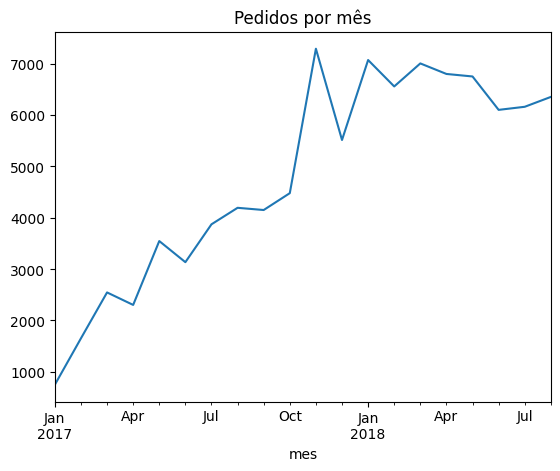

In [22]:
# gráfico com quantidade de pedidos por mês 
metricas['qtd_pedidos'].plot(title='Pedidos por mês')
plt.show()

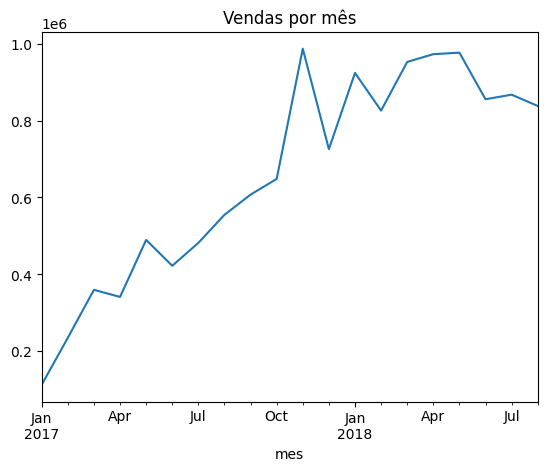

In [23]:
# gráfico com valor vendido por mês
metricas['valor_vendido'].plot(title='Vendas por mês')
plt.show()

In [24]:
# média mensal de pedidos em jan-ago/2018

mascara_2018_metricas = (metricas.index >= '2018-01') & (metricas.index <= '2018-08')
media_mensal_2018 = metricas.loc[mascara_2018_metricas, 'qtd_pedidos'].mean()

print(f'Média mensal de pedidos (jan-ago/2018): {round(media_mensal_2018, 0)}')

Média mensal de pedidos (jan-ago/2018): 6598.0


In [25]:
# pico de novembro/2017 em relação a outubro/2017
pedidos_out_2017 = metricas.loc['2017-10', 'qtd_pedidos']
pedidos_nov_2017 = metricas.loc['2017-11', 'qtd_pedidos']

var_nov_out_2017 = round((pedidos_nov_2017 - pedidos_out_2017) / pedidos_out_2017 * 100, 2)

print(f'Pedidos out/2017: {pedidos_out_2017}')
print(f'Pedidos nov/2017: {pedidos_nov_2017}')
print(f'Variação nov vs out/2017: {var_nov_out_2017}%')

Pedidos out/2017: 4478.0
Pedidos nov/2017: 7289.0
Variação nov vs out/2017: 62.77%


In [26]:
# média mensal de pedidos: 1º quadrimestre vs 2º quadrimestre de 2018

mascara_quad1_2018 = (metricas.index >= '2018-01') & (metricas.index <= '2018-04')
mascara_quad2_2018 = (metricas.index >= '2018-05') & (metricas.index <= '2018-08')

media_quad1_2018 = metricas.loc[mascara_quad1_2018, 'qtd_pedidos'].mean()
media_quad2_2018 = metricas.loc[mascara_quad2_2018, 'qtd_pedidos'].mean()

# variaçaõ percentual q1 e q2
var_percent_q1q2 = ((media_quad2_2018 - media_quad1_2018) / media_quad1_2018 * 100).round(2)

print(f'Média Q1 2018: {media_quad1_2018}')
print(f'Média Q2 2018: {media_quad2_2018}')
print(f'Variação Percentual Quad 1 vs Quad 2: {var_percent_q1q2}%')

Média Q1 2018: 6856.25
Média Q2 2018: 6339.5
Variação Percentual Quad 1 vs Quad 2: -7.54%


### Resposta: as vendas estão crescendo?

**Cresceram fortemente em 2017, mas estabilizaram em 2018, com leve queda no segundo quadrimestre.**

- Crescimento acumulado: de jan–ago/2017 para jan–ago/2018, os pedidos passaram de 21.998 para 52.783 (+139,9%) e o valor vendido de R$ 2,99 mi para R$ 7,22 mi (+141,1%).
- Origem do crescimento: o ticket mediano subiu apenas 4,8% (R$ 84 → R$ 88). O crescimento veio do volume de pedidos, não de pedidos mais caros.
- Limitação do número: os 140% são inflados pelo efeito base. Jan/2017 teve apenas 750 pedidos, numa operação ainda em início, contra uma média de 6.598 pedidos/mês em 2018. O número reflete principalmente a fase de expansão de 2017.
- Momento atual: em 2018 o crescimento parou. A média mensal de pedidos caiu de 6.856 (jan–abr) para 6.340 (mai–ago), uma queda de 7,54%.
- Ponto fora da curva: o pico de nov/2017 (7.289 pedidos, +62,77% sobre outubro) é provavelmente efeito da Black Friday e não indica mudança de tendência.

Questão em aberto: os dados de vendas não explicam a desaceleração de 2018. Hipóteses a investigar nas próximas perguntas: piora na satisfação dos clientes, nos prazos de entrega, ou perda de força em categorias ou regiões específicas.

# 6.0 Os Clientes Estão Satisfeitos?

In [40]:
# criando uma cópia da tabela de avaliações
df_avaliacoes_new = df_avaliacoes.copy()

In [41]:
# apagando coluna que não será usada
df_avaliacoes_new = df_avaliacoes_new.drop(columns=['review_id'])

In [42]:
# criando coluna com nova classificação das avaliações
classificacao = {1: 'insatisfeito', 2: 'insatisfeito', 3: 'neutro', 4: 'satisfeito', 5:'satisfeito'}
df_avaliacoes_new['avaliacao_new'] = df_avaliacoes_new['review_score'].map(classificacao)

In [43]:
# checando a classificação: cada nota deve aparecer em um único grupo
pd.crosstab(df_avaliacoes_new['review_score'], df_avaliacoes_new['avaliacao_new'])

avaliacao_new,insatisfeito,neutro,satisfeito
review_score,,,
1,9251,0,0
2,2895,0,0
3,0,7839,0
4,0,0,18749
5,0,0,56311


In [44]:
# checando nulos na avaliação
df_avaliacoes_new['avaliacao_new'].isna().sum()

np.int64(0)

In [45]:
# junção com a tabela de pedidos (apenas id e data da compra)
pedidos_avaliacoes = pd.merge(
    df_pedidos[['order_id', 'order_purchase_timestamp']],
    df_avaliacoes_new,
    how='inner',
    on='order_id',
    validate='1:1'
)

In [46]:
# checando se a tabela tem 95.045 linhas
pedidos_avaliacoes.shape

(95045, 4)

In [47]:
# calculando o percentual de avaliações de acordo com a nova classificação
proporcao_reviews = pd.DataFrame({
    "quantidade": pedidos_avaliacoes["avaliacao_new"].value_counts(),
    "percentual": (pedidos_avaliacoes["avaliacao_new"].value_counts(normalize=True)*100).round(2)})

proporcao_reviews

,quantidade,percentual
avaliacao_new,,
satisfeito,75060,78.97
insatisfeito,12146,12.78
neutro,7839,8.25


In [48]:
# criando a coluna do mês da avaliação
pedidos_avaliacoes['mes'] = pedidos_avaliacoes['order_purchase_timestamp'].dt.to_period('M')

In [49]:
pedidos_avaliacoes.head()

,order_id,order_purchase_timestamp,review_score,avaliacao_new,mes
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,4,satisfeito,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,4,satisfeito,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,5,satisfeito,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,5,satisfeito,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,5,satisfeito,2018-02


In [ ]:
'''
Etapa 2: insatisfeitos por mês

Depois:

Crie a coluna de mês a partir da data da compra, como na pergunta 1.
Calcule o percentual de insatisfeitos por mês: agrupe por mês e tire a média de coluna == 'insatisfeito', multiplicando por 100.
Faça o gráfico de linha.

Ao olhar o gráfico, tenha em mente a questão em aberto: a insatisfação piora em 2018, no mesmo período em que as vendas param de crescer?
'''

### Resposta: os clientes estão satisfeitos?

**XYZ**

- Satisfação geral: 78,97% das avaliações são de clientes satisfeitos (notas 4 e 5), 8,25% neutras (nota 3) e 12,78% insatisfeitas (notas 1 e 2).
- Efeito do recorte: em relação à base bruta, os insatisfeitos caíram de 14,69% para 12,78%, e os satisfeitos subiram de 77,07% para 78,97%. Isso era esperado pois, a análise considera apenas pedidos entregues. Pedidos cancelados ou indisponíveis tendem a gerar avaliações piores. Os neutros praticamente não mudaram (8,24% -> 8,25%).
- 

# 7.0 O que Prejudica a Satisfação de um Cliente?

# 8.0 Onde Estão as Oportunidades?

# 9.0 Conclusão e Recomendação